<img src="https://raw.githubusercontent.com/carubbi/MQ/b58af070c45fb17b77640c06c0016859ad366b4d/notebooks/assets/imgs/UNIFOR_logo.png" width="400">
<br>
<b>
<font size="6" face="arial" color="blue">
    Graduação em Ciência da Computação
</font>
</b>
<br>
<b>
<font size="4" face="arial">
    Disciplina: Métodos Quantitativos em Computação
</font>
</b>

**Orientador: Prof. Me. Ricardo Carubbi** <br>
*Docente da Graduação e Pós-Graduação em Ciência de Dados e Inteligência Artificial*<br>
*Laboratório de Ciência de Dados e Inteligência Artificial*<br>
*Universidade de Fortaleza*<br>

# Unidade III — Regressão linear simples e diagnóstico

Como o comprimento da nadadeira se relaciona com a massa corporal média dos pinguins do arquipélago Palmer? Vamos descrever essa relação com uma reta, quantificar a incerteza da inclinação e usar os resíduos para avaliar a adequação do modelo.

O trabalho retoma o diagrama de dispersão e a covariância da Unidade I, esperança e independência da Unidade II e erro-padrão, intervalos de confiança e testes da Unidade III.

## 1. Objetivos de aprendizagem

Ao final da aula, o aluno será capaz de:

- Avaliar no diagrama de dispersão se há relação linear entre a variável resposta e o preditor.
- Calcular e interpretar o resíduo, a diferença entre o valor observado e o valor indicado pela reta.
- Ajustar a reta e interpretar a inclinação como variação da resposta média por unidade do preditor.
- Comparar a reta com a média geral e interpretar a diferença no ajuste.
- Interpretar o intervalo de confiança da inclinação e testar, pelo valor-p, se ela é zero.
- Interpretar padrões nos resíduos para avaliar a adequação do modelo e os limites da inferência.

## 2. Agenda

### 2.1. Aula 5 — Da dispersão à reta de regressão

1. Da dispersão à pergunta de regressão — 20 min
2. Da média geral à reta de regressão — 35 min
3. Como escolher a reta por mínimos quadrados ordinários (OLS) — 45 min

### 2.2. Aula 6 — Qualidade do ajuste e inferência na regressão

1. Conferência do ajuste com `ols()` e interpretação dos coeficientes — 25 min
2. Comparação da reta com a média geral — 20 min
3. Intervalo de confiança e teste de hipótese para a inclinação — 25 min
4. Acompanhamento 1 da AP3 — 30 min

### 2.3. Abertura da Aula 9 — Diagnóstico

1. Resíduos versus valores ajustados — 8 min
2. Gráfico Q–Q — 7 min
3. Parecer em dupla — 5 min

As figuras já estão disponíveis para leitura. Use a equação fornecida na seção 6 para o primeiro resíduo. Na seção 7, você obterá a mesma reta por mínimos quadrados.

## 3. Importações e configurações

### 3.1. Bibliotecas

Pandas organiza a base e as tabelas. Seaborn é a biblioteca principal para os gráficos, com Matplotlib para controlar os eixos e as anotações. Statsmodels ajusta o modelo, fornece a saída de regressão e gera o gráfico Q–Q.

In [1]:
# Importa as bibliotecas usadas nas três aulas.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from statsmodels.api import qqplot
from statsmodels.formula.api import ols

### 3.2. Apresentação de tabelas e gráficos

As cores e os marcadores identificam as espécies. As unidades aparecem nos eixos dos gráficos e nos rótulos das tabelas.

In [2]:
# Define o formato de exibição das tabelas.
pd.options.display.float_format = "{:,.4f}".format

# Define a aparência dos gráficos por espécie.
sns.set_theme(style="whitegrid", context="notebook", rc={"figure.dpi": 120})
especies = ["Adelie", "Chinstrap", "Gentoo"]
cores = {"Adelie": "#B34B15", "Chinstrap": "#2469A0", "Gentoo": "#207B66"}
marcadores = {"Adelie": "o", "Chinstrap": "^", "Gentoo": "s"}

### 3.3. Funções auxiliares

As funções abaixo padronizam a apresentação de tabelas e de diagramas com cores e marcadores por espécie.

In [3]:
# Apresenta uma tabela com os nomes das medidas como índice.
def exibir_medidas(medidas):
    display(pd.DataFrame.from_dict(medidas, orient="index", columns=["Valor"]))


# Desenha um diagrama de dispersão com a mesma codificação nas três aulas.
def dispersao_por_especie(dados, coluna_x, coluna_y, rotulo_x, rotulo_y, ax):
    sns.scatterplot(
        data=dados, x=coluna_x, y=coluna_y, hue="SPECIES", style="SPECIES",
        hue_order=especies, style_order=especies, palette=cores,
        markers=marcadores, alpha=0.67, s=35, linewidth=0, ax=ax,
    )
    ax.set(xlabel=rotulo_x, ylabel=rotulo_y)
    ax.legend(title="Espécie", frameon=True)

## 4. Carregamento e seleção dos dados

### 4.1. Carregamento dos dados

Carregue a base pré-processada em `data/processed/penguins.csv», a partir da raiz do repositório, e visualize as cinco primeiras linhas. Localize as colunas de massa corporal, comprimento da nadadeira e espécie.

In [4]:
# Localiza a base no repositório e abre os cinco primeiros registros.
pasta = Path.cwd().resolve()
arquivo = Path("data/processed/penguins.csv")
raiz = next(p for p in (pasta, *pasta.parents) if (p / arquivo).is_file())
df = pd.read_csv(raiz / arquivo)
display(df.head())

,ID,SPECIES,ISLAND,SEX,DATE_EGG,YEAR,CULMEN_LENGTH,CULMEN_DEPTH,FLIPPER_LENGTH,BODY_MASS
0,PAL0708_N1A1,Adelie,Torgersen,male,2007-11-11,2007,39.1000,18.7000,181.0000,"3,750.0000"
1,PAL0708_N1A2,Adelie,Torgersen,female,2007-11-11,2007,39.5000,17.4000,186.0000,"3,800.0000"
2,PAL0708_N2A1,Adelie,Torgersen,female,2007-11-16,2007,40.3000,18.0000,195.0000,"3,250.0000"
3,PAL0708_N2A2,Adelie,Torgersen,NaN,2007-11-16,2007,NaN,NaN,NaN,NaN
4,PAL0708_N3A1,Adelie,Torgersen,female,2007-11-16,2007,36.7000,19.3000,193.0000,"3,450.0000"


**Tabela 1 — Prévia da base de pinguins.** O comprimento da nadadeira foi medido em milímetros e a massa corporal, em gramas. Dados de Horst, Hill e Gorman (2022).

### 4.2. Seleção e conferência dos registros

Separe os registros com `BODY_MASS», `FLIPPER_LENGTH» e `SPECIES» observados. Informe quantos registros foram carregados, quantos foram excluídos e quantos entrarão no ajuste. Preserve esse recorte para comparar os resultados ao longo da aula.

In [5]:
# Seleciona os casos completos para as variáveis usadas na aula.
variaveis = ["BODY_MASS", "FLIPPER_LENGTH", "SPECIES"]
dados = df.dropna(subset=variaveis).copy()
n = len(dados)
exibir_medidas({"Carregados": len(df), "Excluídos": len(df) - n, "Usados": n})

,Valor
Carregados,344
Excluídos,2
Usados,342


**Tabela 2 — Registros usados no ajuste.** Dos 344 registros carregados, 2 foram excluídos por ausência de massa e comprimento de nadadeira. A regressão usa os 342 registros restantes.

## 5. Da dispersão à pergunta de regressão

### 5.1. Contexto

A matriz apresenta quatro medidas corporais dos pinguins. Observe o painel de massa corporal e comprimento da nadadeira. No diagrama em destaque, cada ponto identifica um pinguim. O eixo horizontal mede o comprimento da nadadeira em milímetros, e o vertical mede a massa corporal em gramas.

**Pergunta de regressão.** Como a massa corporal média varia com o comprimento da nadadeira?

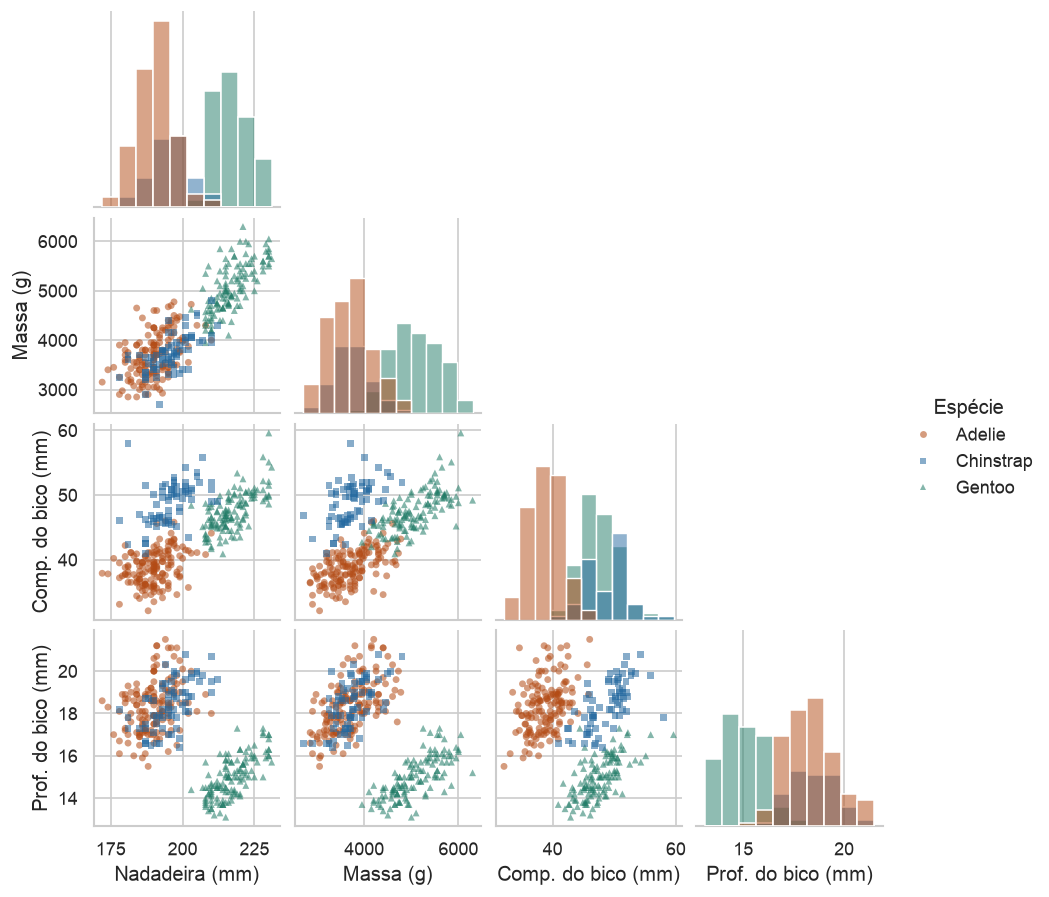

In [6]:
# Apresenta a distribuição e as relações entre quatro medidas corporais.
nomes = {
    "FLIPPER_LENGTH": "Nadadeira (mm)",
    "BODY_MASS": "Massa (g)",
    "CULMEN_LENGTH": "Comp. do bico (mm)",
    "CULMEN_DEPTH": "Prof. do bico (mm)",
}
medidas = dados.rename(columns=nomes)
matriz = sns.pairplot(
    medidas, vars=list(nomes.values()), hue="SPECIES", hue_order=especies,
    markers=list(marcadores.values()), palette=cores, diag_kind="hist",
    corner=True, height=1.9, plot_kws={"s": 17, "alpha": 0.55, "linewidth": 0},
)
matriz.legend.set_title("Espécie")
plt.show()

**Figura 1 — Distribuições e relações entre as medidas corporais, por espécie.** A diagonal apresenta histogramas. Os outros painéis mostram as relações entre pares de medidas. Visualização produzida com Seaborn a partir da [Figura 2 de Horst, Hill e Gorman (2022)](https://journal.r-project.org/articles/RJ-2022-020/#fig:iris-penguin-scatters).

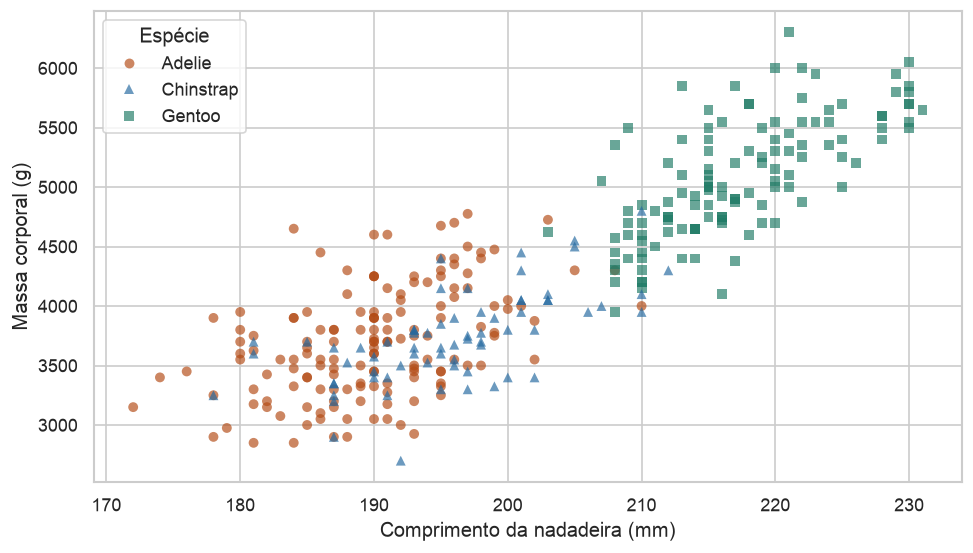

In [7]:
# Isola a relação entre comprimento da nadadeira e massa corporal.
rotulo_x = "Comprimento da nadadeira (mm)"
rotulo_y = "Massa corporal (g)"
figura, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
dispersao_por_especie(dados, "FLIPPER_LENGTH", "BODY_MASS", rotulo_x, rotulo_y, ax)
plt.show()

**Figura 2 — Massa corporal e comprimento da nadadeira.** Cada ponto representa um pinguim. Aplicação inspirada na [Figura 4 de Horst, Hill e Gorman (2022)](https://journal.r-project.org/articles/RJ-2022-020/).

### 5.2. Fundamentação teórica

A **correlação de Pearson** resume a direção e a intensidade da associação linear entre duas variáveis quantitativas. Seu valor é o mesmo quando trocamos as variáveis de eixo. Na regressão, a pergunta define a **variável resposta** $Y$, cuja média queremos descrever, e o **preditor** $X$, usado para estimar essa média.

Uma reta é uma primeira aproximação quando a média da resposta acompanha uma direção aproximadamente linear. Curvaturas ou agrupamentos no diagrama ajudam a reconhecer limitações dessa aproximação. A interpretação causal exige evidências sobre o desenho do estudo (Barbetta, Reis e Bornia, 2010, §§ 11.1–11.3).

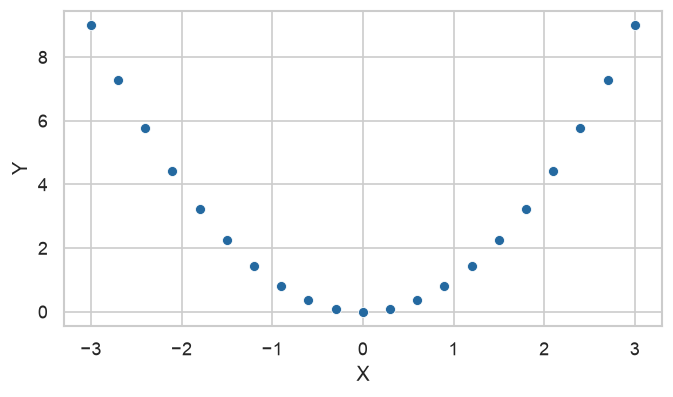

In [8]:
# Ilustra uma associação em curva com correlação linear igual a zero.
x_curva = np.linspace(-3, 3, 21)
figura, ax = plt.subplots(figsize=(5.5, 3.2), layout="constrained")
sns.scatterplot(x=x_curva, y=x_curva**2, color="#2469A0", ax=ax)
ax.set(xlabel="X", ylabel="Y")
plt.show()

**Figura 3 — Relação em curva com correlação linear igual a zero.** Ilustração própria a partir da Figura 7.7 de Navidi (2024, § 7.1, p. 533). O que o diagrama revela sobre a relação que Pearson deixa de captar?

### 5.3. Aplicação

1. Identifique a resposta, o preditor e suas unidades.
2. Descreva a direção e a forma da relação no conjunto. Observe onde os grupos por espécie se separam e onde se sobrepõem.
3. Indique uma característica do gráfico que favorece o uso de uma reta e uma ressalva baseada nos agrupamentos.
4. Localize o pinguim com nadadeira de 181 mm e massa de 3.750 g. Ele será retomado na seção 6.

A resposta é a massa corporal (g), e o preditor é o comprimento da nadadeira (mm). No conjunto, observam-se massas geralmente maiores para nadadeiras mais longas. A direção crescente torna plausível usar uma reta como resumo inicial. Adélie e Chinstrap se sobrepõem em parte, enquanto Gentoo tende a se concentrar em comprimentos e massas maiores. A reta geral resume esses grupos em conjunto e pode ocultar diferenças por espécie.

O pinguim de 181 mm e 3.750 g é Adélie e está na região inferior esquerda do gráfico.

## 6. Da média geral à reta de regressão

### 6.1. Contexto

O pinguim de 181 mm tem massa de 3.750 g. A média geral de 4.201,75 g é a mesma referência para qualquer comprimento de nadadeira. Como muda a estimativa quando consideramos o comprimento desse pinguim?

### 6.2. Fundamentação teórica

A média amostral $\bar y$ resume as massas observadas. A **esperança** é uma média teórica. A **média condicional** $\operatorname{E}(Y\mid X=x)$ descreve a média teórica de $Y$ para um dado valor $x$ de $X$. No modelo de regressão linear simples,

$$
\operatorname{E}(Y\mid X=x)=\beta_0+\beta_1x.
\tag{5.1}
$$

O **intercepto** $\beta_0$ é a média da resposta em $x=0$. A **inclinação** $\beta_1$ indica a variação nessa média quando o preditor aumenta uma unidade.

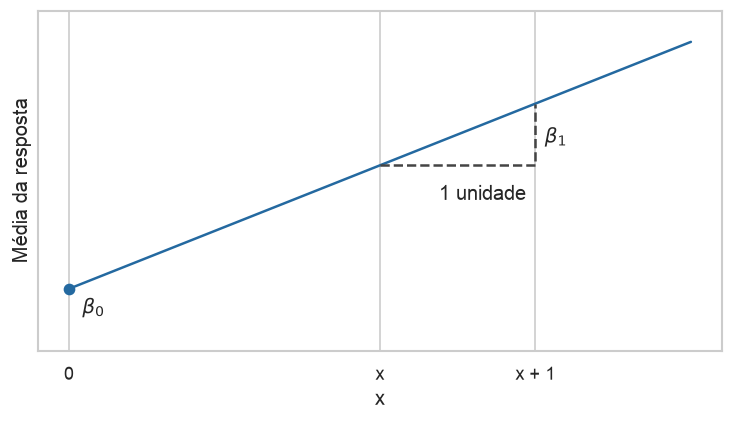

In [9]:
# Ilustra o intercepto e a inclinação em uma reta genérica.
figura, ax = plt.subplots(figsize=(6, 3.4), layout="constrained")
ax.plot([0, 4], [1, 3], color="#2469A0")
ax.scatter([0], [1], color="#2469A0")
ax.plot([2, 3, 3], [2, 2, 2.5], "--", color="#444444")
ax.annotate(r"$\beta_0$", (0, 1), xytext=(8, -15), textcoords="offset points")
ax.text(2.38, 1.72, "1 unidade")
ax.text(3.06, 2.18, r"$\beta_1$")
ax.set(xlim=(-0.2, 4.2), ylim=(0.5, 3.25), xlabel="x", ylabel="Média da resposta")
ax.set_xticks([0, 2, 3], ["0", "x", "x + 1"])
ax.set_yticks([])
plt.show()

**Figura 4 — Intercepto e inclinação da média condicional.** Esquema elaborado a partir da Figura 16.2 de Morettin e Bussab (2010, § 16.1, p. 450). A obra representa o intercepto por α e a inclinação por β.

Para uma observação $i$, sejam $x_i$ o valor observado do preditor e $y_i$ a resposta observada. O **valor ajustado** é

$$
\hat y_i=\hat\beta_0+\hat\beta_1x_i,
\tag{5.2}
$$

em que $\hat\beta_0$ e $\hat\beta_1$ são as estimativas do intercepto e da inclinação calculadas na amostra. O **resíduo** é a diferença entre a resposta observada e o valor ajustado,

$$
e_i=y_i-\hat y_i.
\tag{5.3}
$$

O resíduo é medido na unidade da resposta. Ele é positivo acima da reta, negativo abaixo dela e zero sobre ela. Seu módulo é a distância vertical entre o ponto e a reta.

O modelo para a observação é

$$
Y_i=\beta_0+\beta_1X_i+\varepsilon_i.
\tag{5.4}
$$

$Y_i$ e $X_i$ representam a resposta e o preditor da observação. O **erro aleatório** $\varepsilon_i$ é o desvio em relação à média condicional teórica. Como essa média é desconhecida, usamos os resíduos do ajuste para estudar os erros (Barbetta, Reis e Bornia, 2010, § 11.3, p. 325–328).

### 6.3. Aplicação

Para esta atividade, use a reta ajustada já fornecida. Na equação, $x$ é o comprimento da nadadeira em mm e $\hat y$ é a massa ajustada em g.

$$
\hat y=-5780{,}831358+49{,}685566x.
\tag{5.5}
$$

1. Calcule a diferença entre a massa observada do pinguim de 181 mm e a média geral de 4.201,75 g.
2. Substitua 181 mm na reta e calcule o resíduo. Arredonde o resultado a duas casas decimais.
3. Use a figura para interpretar o sinal e a magnitude das duas diferenças.

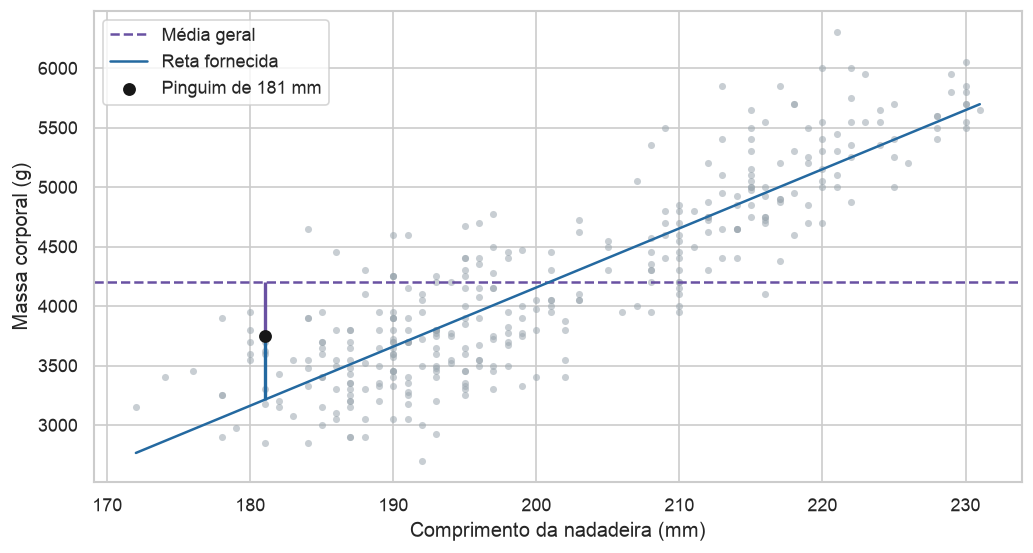

In [10]:
# Prepara as referências fornecidas para a primeira leitura do resíduo.
x = dados["FLIPPER_LENGTH"]
y = dados["BODY_MASS"]
x_bar, y_bar = x.mean(), y.mean()
passo_x = np.array([x.min(), x.max()])
x_p, y_p = 181, 3750
b0_dado, b1_dado = -5780.831358, 49.685566
y_p_dado = b0_dado + b1_dado * x_p

# Destaca a mesma observação em relação às duas referências.
figura, ax = plt.subplots(figsize=(8.5, 4.5), layout="constrained")
sns.scatterplot(data=dados, x="FLIPPER_LENGTH", y="BODY_MASS",
                s=18, color="#9BA7AF", linewidth=0, alpha=0.55, ax=ax)
ax.axhline(y_bar, color="#6951A2", linestyle="--", label="Média geral")
ax.plot(passo_x, b0_dado + b1_dado * passo_x, color="#2469A0", label="Reta fornecida")
ax.vlines(x_p, y_p, y_bar, color="#6951A2", linewidth=2)
ax.vlines(x_p, y_p_dado, y_p, color="#2469A0", linewidth=2)
ax.scatter(x_p, y_p, color="#171717", s=45, zorder=5, label="Pinguim de 181 mm")
ax.set(xlabel=rotulo_x, ylabel=rotulo_y)
ax.legend()
plt.show()

**Figura 5 — Massa observada e duas referências.** Segmentos verticais ligam o pinguim à média geral e à reta fornecida. Dados de Horst, Hill e Gorman (2022).

In [11]:
# Calcula as diferenças em relação à média e à reta fornecida.
exibir_medidas({
    "Diferença em relação à média geral (g)": y_p - y_bar,
    "Massa indicada pela reta fornecida (g)": y_p_dado,
    "Resíduo (g)": y_p - y_p_dado,
})

,Valor
Diferença em relação à média geral (g),-451.7544
Massa indicada pela reta fornecida (g),"3,212.2561"
Resíduo (g),537.7439


O pinguim está **451,75 g abaixo da média geral**. Para 181 mm, a reta indica **3.212,26 g**. O resíduo é **+537,74 g**. O pinguim é mais leve que a média geral e mais pesado do que indica a reta para esse comprimento de nadadeira.

## 7. Como escolher a reta por mínimos quadrados ordinários (OLS)

### 7.1. Contexto

Duas retas candidatas passam pelo ponto das médias, $(\bar x,\bar y)$, com inclinações de 30 e 60 g/mm. Cada reta se aproxima mais de pontos diferentes. Como compará-las com um único critério?

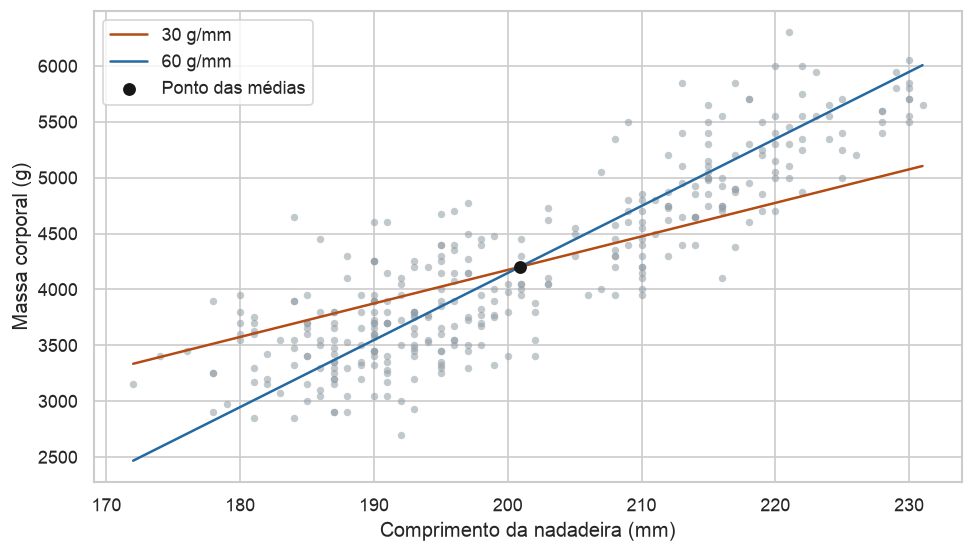

In [12]:
# Mostra duas retas que passam pelo mesmo ponto das médias.
figura, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
sns.scatterplot(data=dados, x="FLIPPER_LENGTH", y="BODY_MASS",
                s=20, color="#919DA5", linewidth=0, alpha=0.55, ax=ax)
ax.plot(passo_x, y_bar + 30 * (passo_x - x_bar), color="#B34B15", label="30 g/mm")
ax.plot(passo_x, y_bar + 60 * (passo_x - x_bar), color="#2469A0", label="60 g/mm")
ax.scatter(x_bar, y_bar, color="#171717", s=45, zorder=5, label="Ponto das médias")
ax.set(xlabel=rotulo_x, ylabel=rotulo_y)
ax.legend()
plt.show()

**Figura 6 — Retas candidatas.** Ambas passam pelo ponto das médias. A diferença entre elas está na inclinação. Dados de Horst, Hill e Gorman (2022).

### 7.2. Fundamentação teórica

Somar os resíduos com sinal permite que diferenças positivas e negativas se anulem. O método de **mínimos quadrados ordinários** escolhe a reta que minimiza a soma dos quadrados dessas diferenças. Para uma reta candidata com intercepto $b_0$ e inclinação $b_1$, calculamos

$$
\mathrm{SQR}(b_0,b_1)=\sum_{i=1}^{n}[y_i-(b_0+b_1x_i)]^2,
\tag{5.6}
$$

em que $n$ é o número de observações. A Figura 7 destaca as diferenças que entram nessa soma.

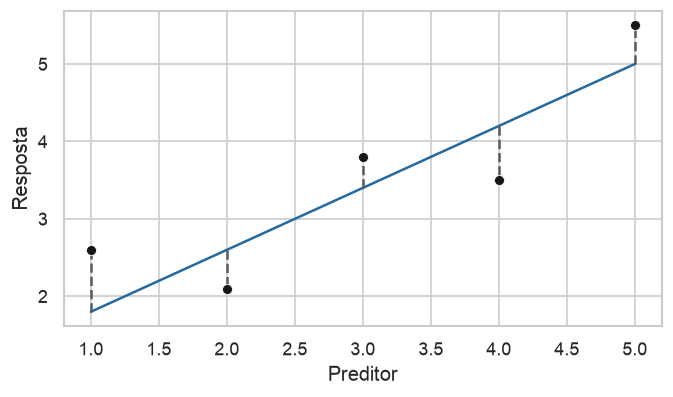

In [13]:
# Ilustra as diferenças verticais que entram no critério de mínimos quadrados.
x_esq = np.array([1, 2, 3, 4, 5])
y_reta = 1 + 0.8 * x_esq
y_esq = y_reta + np.array([0.8, -0.5, 0.4, -0.7, 0.5])
figura, ax = plt.subplots(figsize=(5.5, 3.2), layout="constrained")
ax.plot(x_esq, y_reta, color="#2469A0")
ax.vlines(x_esq, y_reta, y_esq, color="#545B61", linestyle="--")
sns.scatterplot(x=x_esq, y=y_esq, color="#171717", ax=ax, zorder=5)
ax.set(xlabel="Preditor", ylabel="Resposta")
plt.show()

**Figura 7 — Diferenças verticais entre valores observados e valores na reta.** Esquema elaborado a partir da Figura 11.3 de Montgomery e Runger (2018, § 11.2, p. 285).

Para obter a reta de mínimos quadrados, retomamos a covariância amostral $s_{xy}$ e a variância amostral do preditor $s_x^2$ da Unidade I. Com $s_x^2>0$,

$$
\hat\beta_1=\frac{s_{xy}}{s_x^2},\qquad
\hat\beta_0=\bar y-\hat\beta_1\bar x.
\tag{5.7}
$$

A reta ajustada passa pelo ponto $(\bar x,\bar y)$, em que $\bar x$ e $\bar y$ são as médias amostrais do preditor e da resposta (Barbetta, Reis e Bornia, 2010, § 11.3.1, p. 326–330).

### 7.3. Aplicação

#### 7.3.1. Implementação sem pacote estatístico

1. Obtenha o intercepto de cada reta candidata a partir da inclinação e do ponto das médias.
2. Calcule os valores indicados pelas retas e os resíduos em cada um dos 342 registros. Some os quadrados dos resíduos de cada reta.
3. Calcule a inclinação e o intercepto da reta de mínimos quadrados.
4. Calcule os valores ajustados, os resíduos e a soma dos quadrados dos resíduos da reta obtida. Compare com as duas candidatas.

In [14]:
# Obtém os valores indicados e os resíduos para as duas candidatas.
a30 = y_bar - 30 * x_bar
a60 = y_bar - 60 * x_bar
e30 = y - (a30 + 30 * x)
e60 = y - (a60 + 60 * x)
sqr30 = (e30**2).sum()
sqr60 = (e60**2).sum()

# Calcula a reta de mínimos quadrados e a soma de quadrados residual.
b1 = x.cov(y) / x.var()
b0 = y_bar - b1 * x_bar
y_aj = b0 + b1 * x
e = y - y_aj
sqr = (e**2).sum()

# Compara o critério das três retas.
tab_retas = pd.DataFrame({
    "Intercepto (g)": [a30, a60, b0],
    "Inclinação (g/mm)": [30, 60, b1],
    "Soma dos resíduos (g)": [e30.sum(), e60.sum(), e.sum()],
    "SQR (g²)": [sqr30, sqr60, sqr],
}, index=["Candidata 30", "Candidata 60", "Ajuste por mínimos quadrados"])
display(tab_retas)

,Intercepto (g),Inclinação (g/mm),Soma dos resíduos (g),SQR (g²)
Candidata 30,"-1,825.7018",30.0000,0.0000,"78,984,031.5789"
Candidata 60,"-7,853.1579",60.0000,0.0000,"60,028,139.4737"
Ajuste por mínimos quadrados,"-5,780.8314",49.6856,0.0000,"52,854,795.6284"


**Tabela 3 — Comparação das retas nos 342 registros.** A soma dos quadrados dos resíduos é de aproximadamente 78,98 milhões de g² para a candidata de 30 g/mm, 60,03 milhões para a candidata de 60 g/mm e 52,85 milhões para a reta ajustada.

#### 7.3.2. Interpretação

1. Identifique a reta com menor soma dos quadrados dos resíduos.
2. Explique por que a soma dos resíduos com sinal é zero nas três retas.
3. Interprete a inclinação em g/mm. Para interpretar o intercepto, verifique se zero está na faixa observada de comprimentos.
4. Calcule novamente o resíduo do pinguim de 181 mm e compare com o valor obtido na seção 6.

In [15]:
# Confere a faixa do preditor e o resíduo da observação retomada.
exibir_medidas({
    "Menor comprimento (mm)": x.min(),
    "Maior comprimento (mm)": x.max(),
    "Massa ajustada para 181 mm (g)": b0 + b1 * x_p,
    "Resíduo para 181 mm (g)": y_p - (b0 + b1 * x_p),
})

,Valor
Menor comprimento (mm),172.0000
Maior comprimento (mm),231.0000
Massa ajustada para 181 mm (g),"3,212.2562"
Resíduo para 181 mm (g),537.7438


A reta de mínimos quadrados tem a menor soma dos quadrados dos resíduos. A média dos valores em cada reta é $\bar y$, pois todas passam por $(\bar x,\bar y)$. Assim, a soma dos resíduos com sinal se anula em todas, mesmo com somas de quadrados diferentes.

A reta indica um aumento de **49,69 g na massa média estimada por milímetro a mais de nadadeira**. O intercepto de −5.780,83 g é o valor que a equação indicaria para 0 mm. Essa leitura extrapola o intervalo observado de 172 a 231 mm. O resíduo arredondado a duas casas é **+537,74 g**, como na seção 6.

## 8. Ajuste e inferência nos 342 pinguins

### 8.1. Contexto

A Aula 5 obteve uma reta para comprimentos de nadadeira entre 172 e 231 mm. Quanto essa reta melhora o ajuste em relação à média geral? Qual é a incerteza da inclinação estimada?

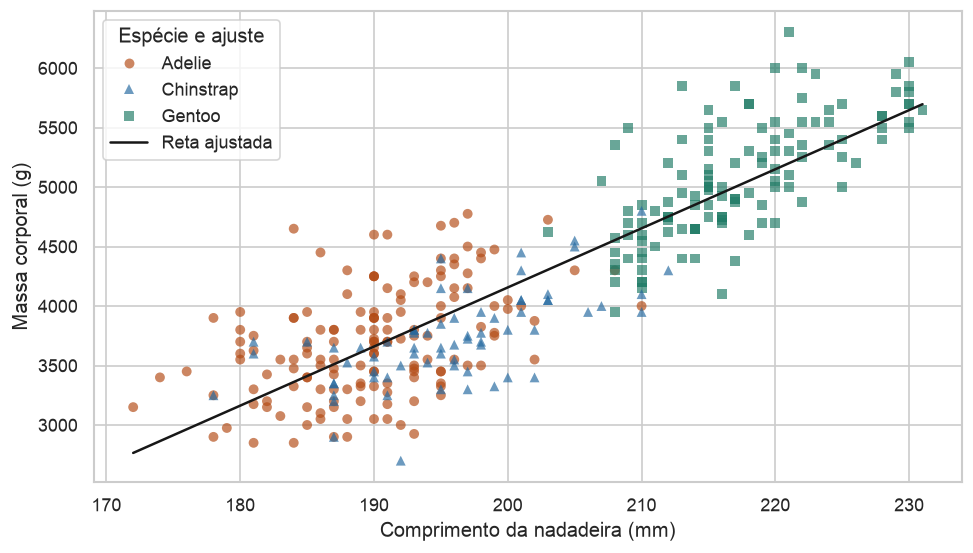

In [16]:
# Retoma a reta calculada por mínimos quadrados.
figura, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
dispersao_por_especie(dados, "FLIPPER_LENGTH", "BODY_MASS", rotulo_x, rotulo_y, ax)
ax.plot(passo_x, b0 + b1 * passo_x, color="#171717", label="Reta ajustada")
ax.legend(title="Espécie e ajuste", frameon=True)
plt.show()

**Figura 8 — Reta ajustada aos 342 registros.** A linha é exibida no intervalo observado do preditor. Dados de Horst, Hill e Gorman (2022).

### 8.2. Fundamentação teórica

**Coeficientes.** A inclinação é a variação média estimada por unidade do preditor. O intercepto é o valor médio estimado quando o preditor vale zero. Vale conferir a faixa do preditor antes de interpretar esse valor.

**Qualidade do ajuste.** A Figura 5 mostra duas referências para a mesma observação. Retome os dois segmentos para distinguir o desvio em relação à média do resíduo em relação à reta. Essa comparação também é ilustrada na Figura 11.7 de Barbetta, Reis e Bornia (2010, p. 330). Para todos os registros, calculamos

$$
\mathrm{SQT}=\sum_{i=1}^{n}(y_i-\bar y)^2,\qquad \mathrm{SQR}=\sum_{i=1}^{n}e_i^2.
\tag{6.1}
$$

$\mathrm{SQT}$ é a soma dos quadrados em relação à média geral e $\mathrm{SQR}$ é a soma dos quadrados dos resíduos. Com $\mathrm{SQT}>0$, o **coeficiente de determinação** $R^2$ é a redução proporcional da soma de quadrados ao usar a reta no lugar da média geral. O **$R^2$ ajustado** leva em conta os graus de liberdade de cada referência. Para a regressão simples com intercepto e $n>2$,

$$
R^2=1-\frac{\mathrm{SQR}}{\mathrm{SQT}}, \qquad
R^2_{\mathrm{ajustado}}
=1-\frac{\mathrm{SQR}/(n-2)}{\mathrm{SQT}/(n-1)}.
\tag{6.2}
$$

A média geral usa um parâmetro estimado e tem $n-1$ graus de liberdade. A reta usa dois, o intercepto e a inclinação, e tem $n-2$ graus de liberdade residuais (Montgomery e Runger, 2018, § 12.2.1).

**Condições da inferência clássica.** A média condicional segue uma reta e os erros são independentes entre observações e têm variância constante, dados os valores do preditor. A normalidade condicional dos erros, junto a essas condições, sustenta a referência $t$ exata em amostras finitas. A seção 9 retoma essas condições.

**Erro-padrão da inclinação.** Nas distribuições amostrais, usamos o erro-padrão para descrever a variabilidade de uma estimativa entre amostras. Para a inclinação, estimamos

$$
\operatorname{EP}(\hat\beta_1)=
\sqrt{\frac{\mathrm{SQR}/(n-2)}{\sum_{i=1}^{n}(x_i-\bar x)^2}}.
\tag{6.3}
$$

O numerador dentro da raiz é a variância residual estimada. O denominador mede a dispersão do preditor em torno de sua média e deve ser positivo. Para uma mesma dispersão do preditor, mais variabilidade residual aumenta o erro-padrão.

**Intervalo de confiança e teste.** Retome a ideia de estimativa mais ou menos margem de erro da aula sobre a média. O intervalo para $\beta_1$ é

$$
\hat\beta_1\pm t_{1-\alpha/2,n-2}\operatorname{EP}(\hat\beta_1).
\tag{6.4}
$$

$1-\alpha$ é o nível de confiança e $t_{1-\alpha/2,n-2}$ é o quantil de ordem $1-\alpha/2$ da distribuição $t$ com $n-2$ graus de liberdade. Para testar $H_0\colon\beta_1=0$ contra $H_1\colon\beta_1\ne0$, calculamos a estatística observada

$$
t_{\mathrm{obs}}=\frac{\hat\beta_1}{\operatorname{EP}(\hat\beta_1)}.
\tag{6.5}
$$

Sob $H_0$ e as condições do modelo, o valor-p bilateral soma a área à esquerda de $-|t_{\mathrm{obs}}|$ com a área à direita de $|t_{\mathrm{obs}}|$ na distribuição $t$ de referência (Barbetta, Reis e Bornia, 2010, § 11.3.3; Montgomery e Runger, 2018, §§ 11.4.1 e 11.5.1).

### 8.3. Aplicação

#### 8.3.1. Conferência do ajuste com `ols()»

1. Use `ols()» e `fit()» para ajustar a massa corporal em função do comprimento da nadadeira nos mesmos 342 registros.
2. Exiba `summary()» e localize a tabela **OLS Regression Results**.
3. Compare intercepto, inclinação, valores ajustados e resíduos com os cálculos da seção 7. A tabela exibe coeficientes arredondados. Para a conferência numérica, use os valores guardados pelo ajuste.
4. Interprete os coeficientes com suas unidades e considere a faixa observada do preditor.

In [17]:
# Ajusta o modelo e exibe a saída de regressão.
ajuste = ols("BODY_MASS ~ FLIPPER_LENGTH", data=dados).fit()
print(ajuste.summary())

                            OLS Regression Results                            
Dep. Variable:              BODY_MASS   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.758
Method:                 Least Squares   F-statistic:                     1071.
Date:                Thu, 26 Nov 2026   Prob (F-statistic):          4.37e-107
Time:                        14:13:25   Log-Likelihood:                -2528.4
No. Observations:                 342   AIC:                             5061.
Df Residuals:                     340   BIC:                             5069.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept      -5780.8314    305.815    -18.

**Tabela 4 — Saída do ajuste por mínimos quadrados.** A linha `Intercept» apresenta o intercepto e a linha `FLIPPER_LENGTH», a inclinação. Em `coef», aparecem aproximadamente −5.780,83 g e 49,69 g/mm, respectivamente.

In [18]:
# Confere os coeficientes, os valores ajustados e os resíduos.
np.testing.assert_allclose(ajuste.params, [b0, b1])
np.testing.assert_allclose(ajuste.fittedvalues, y_aj)
np.testing.assert_allclose(ajuste.resid, e, atol=1e-10)
print("Coeficientes, valores ajustados e resíduos conferidos.")

Coeficientes, valores ajustados e resíduos conferidos.


O pacote reproduz o cálculo direto. O modelo estima uma massa média cerca de 49,69 g maior para cada milímetro a mais de nadadeira. O intercepto descreve a reta em 0 mm, fora dos comprimentos observados.

#### 8.3.2. Comparação com a média geral

1. Calcule a soma dos quadrados dos desvios em relação à média geral. Recupere a soma dos quadrados dos resíduos da seção 7.
2. Calcule $R^2$ e $R^2$ ajustado. Confira os resultados em `R-squared» e `Adj. R-squared» na saída da seção 8.3.1.
3. Explique quanto a reta reduz a soma de quadrados e como a correção pelos graus de liberdade afeta o resultado.

In [19]:
# Calcula a soma de quadrados da média e reutiliza a soma residual.
sqt = ((y - y_bar)**2).sum()
r2 = 1 - sqr / sqt
r2_aj = 1 - (sqr / (n - 2)) / (sqt / (n - 1))

# Exibe e confere as medidas do ajuste.
display(pd.DataFrame({
    "Cálculo direto": [r2, r2_aj],
    "Statsmodels": [ajuste.rsquared, ajuste.rsquared_adj],
}, index=["R²", "R² ajustado"]))
np.testing.assert_allclose([r2, r2_aj], [ajuste.rsquared, ajuste.rsquared_adj])

,Cálculo direto,Statsmodels
R²,0.7590,0.7590
R² ajustado,0.7583,0.7583


**Tabela 5 — Coeficientes de determinação calculados e conferidos.** A reta reduz a soma dos quadrados em cerca de **75,9%** em relação à média geral. O $R^2$ ajustado é ligeiramente menor, cerca de **75,8%**, devido à correção pelos graus de liberdade.

#### 8.3.3. Teste e intervalo para a inclinação

1. Formule as hipóteses do teste bilateral para a inclinação e adote nível de significância de 5%.
2. A partir da soma dos quadrados dos resíduos e da dispersão do preditor, calcule o erro-padrão da inclinação. Obtenha a estatística $t$ e o intervalo de 95%. Use o valor crítico fornecido $t_{0{,}975,340}\approx 1{,}966966$.
3. Confira o erro-padrão em `std err», a estatística em `t» e os limites em `[0.025 0.975]». Localize o valor-p em `P>|t|», associe-o às duas caudas e consulte o valor com mais precisão no objeto ajustado se a tabela exibir `0.000».
4. Interprete o intervalo em g/mm e a evidência contra a hipótese de inclinação zero, considerando as condições do modelo.

In [20]:
# Calcula a variância residual, o erro-padrão e a estatística de teste.
gl = n - 2
sxx = ((x - x_bar)**2).sum()
var_res = sqr / gl
ep_b1 = np.sqrt(var_res / sxx)
t_obs = b1 / ep_b1

# Calcula os limites do intervalo bilateral de 95%.
t_crit = 1.966966
ic_b1 = (b1 - t_crit * ep_b1, b1 + t_crit * ep_b1)

# Compara com a saída armazenada e lê o valor-p com mais precisão.
termo = "FLIPPER_LENGTH"
ic_pac = ajuste.conf_int().loc[termo]
display(pd.DataFrame({
    "Cálculo direto": [ep_b1, t_obs, *ic_b1],
    "Statsmodels": [ajuste.bse[termo], ajuste.tvalues[termo], *ic_pac],
}, index=["Erro-padrão (g/mm)", "Estatística t", "Limite inferior", "Limite superior"]))
np.testing.assert_allclose(
    [ep_b1, t_obs, *ic_b1], [ajuste.bse[termo], ajuste.tvalues[termo], *ic_pac],
)
print(f"Valor-p bilateral da inclinação: {ajuste.pvalues[termo]:.3e}")

,Cálculo direto,Statsmodels
Erro-padrão (g/mm),1.5184,1.5184
Estatística t,32.7222,32.7222
Limite inferior,46.6989,46.6989
Limite superior,52.6722,52.6722


Valor-p bilateral da inclinação: 4.371e-107


**Tabela 6 — Incerteza da inclinação.** O erro-padrão estimado é **1,52 g/mm**, $t_{\mathrm{obs}}\approx32{,}72$ e o intervalo de 95% vai de **46,70 a 52,67 g/mm**.

Sob as condições da inferência clássica, o procedimento produz intervalos que contêm a inclinação populacional em 95% de amostras repetidas. Neste ajuste, os valores compatíveis com os dados segundo o intervalo são positivos. O valor-p de aproximadamente $4{,}37\times10^{-107}$, mostrado como `0.000» por arredondamento em `summary()», é a soma das duas áreas além de $\pm32{,}72$ sob $H_0$. Ao nível de 5%, rejeitamos a hipótese de inclinação zero dentro do modelo. O diagnóstico da seção 9 ajuda a avaliar as condições dessa conclusão.

#### 8.3.4. Acompanhamento 1 da AP3

Com a base do projeto, formule a pergunta e indique a população, a resposta, as candidatas quantitativas e o preditor inicial $X$. Registre a característica $B$ e sua categoria de referência. Examine o diagrama de dispersão e faça o ajuste inicial de `SalePrice ~ X».

## 9. Dos resíduos ao diagnóstico

### 9.1. Contexto

O pinguim de 181 mm tinha massa ajustada de aproximadamente 3.212,26 g e resíduo de +537,74 g. No gráfico da aplicação, o eixo horizontal mostra a massa ajustada e o vertical mostra o resíduo. A linha em zero marca os casos em que a massa observada coincide com a ajustada.

O que os padrões nos resíduos revelam sobre a adequação da reta e os limites da inferência?

### 9.2. Fundamentação teórica

O erro mede o desvio em relação à média condicional teórica. Como essa média é desconhecida, o resíduo fornece evidência indireta sobre o erro. Em mínimos quadrados com intercepto, a média dos resíduos é zero por construção. O diagnóstico examina o que acontece ao longo dos valores ajustados.

- **L — Linearidade.** A média condicional varia em linha reta com o preditor. Curvatura sistemática nos resíduos põe essa forma em questão.
- **I — Independência.** Dados os valores do preditor, conhecer o erro de uma observação ou de um grupo de observações não altera a distribuição do erro de outra observação. Avalie essa condição pelo desenho da coleta.
- **N — Normalidade.** Para cada valor do preditor, o modelo clássico supõe uma distribuição Normal para os erros. O gráfico **Q–Q** compara quantis observados dos resíduos com quantis de uma Normal. Alinhamento aproximado fornece evidência indireta de compatibilidade. Desvios sistemáticos, por exemplo nas caudas, indicam pontos a investigar.
- **E — Espalhamento constante.** A variância dos erros é a mesma ao longo do preditor. Uma faixa em funil no gráfico dos resíduos sugere variância desigual.

Sob uma média condicional bem especificada, independência e variância constante sustentam o cálculo clássico dos erros-padrão. A normalidade, junto às demais condições, sustenta a referência $t$ exata usada nos intervalos e testes em amostras finitas (Morettin e Bussab, 2010, § 16.5; Montgomery e Runger, 2018, § 11.7.1).

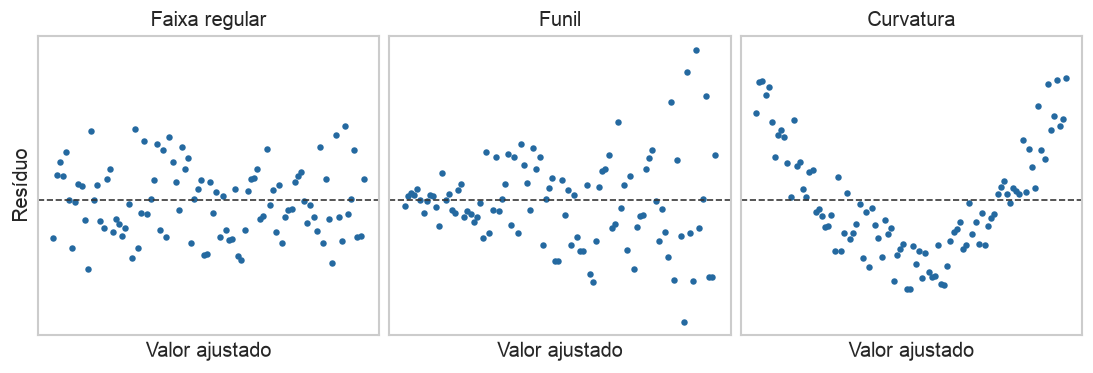

In [21]:
# Simula três padrões para orientar a leitura dos resíduos.
rng = np.random.default_rng(35)
z = np.linspace(-1, 1, 100)
ruido = rng.normal(0, 0.3, len(z))
padroes = [
    ("Faixa regular", ruido),
    ("Funil", ruido * (1.15 + z)),
    ("Curvatura", ruido * 0.6 + 1.5 * (z**2 - np.mean(z**2))),
]
figura, axs = plt.subplots(1, 3, figsize=(9, 3), sharey=True, layout="constrained")
for ax, (titulo, resid) in zip(axs, padroes):
    sns.scatterplot(x=z, y=resid, color="#2469A0", s=15, linewidth=0, ax=ax)
    ax.axhline(0, color="#373737", linestyle="--", linewidth=1)
    ax.set(title=titulo, xlabel="Valor ajustado", xticks=[], yticks=[])
axs[0].set_ylabel("Resíduo")
plt.show()

**Figura 9 — Padrões ilustrativos de resíduos.** Uma faixa regular tem largura semelhante ao longo do eixo. O funil ilustra mudança na dispersão e a curvatura ilustra uma média condicional cuja forma a reta pode deixar de captar. Esquema elaborado a partir da Figura 11.9 de Montgomery e Runger (2018, p. 297).

### 9.3. Aplicação

Use os dois gráficos prontos, gerados para o mesmo ajuste. Os 342 registros analisados têm identificadores distintos. Os pinguins foram medidos em três ilhas do arquipélago Palmer ao longo de três anos, de 2007 a 2009. [Horst, Hill e Gorman (2022)](https://journal.r-project.org/articles/RJ-2022-020/)

1. **Resíduos versus valores ajustados.** Localize o pinguim retomado. Examine curvatura, mudanças na dispersão e padrões por espécie.
2. **Gráfico Q–Q.** Localize desvios da reta de referência e interprete o que sugerem sobre a normalidade dos erros.
3. **Parecer.** Registre uma conclusão de cada gráfico e uma ressalva sobre a inferência. Use os identificadores, as ilhas e os anos de coleta para discutir se há indícios de medições repetidas ou agrupamentos que possam tornar as observações dependentes.

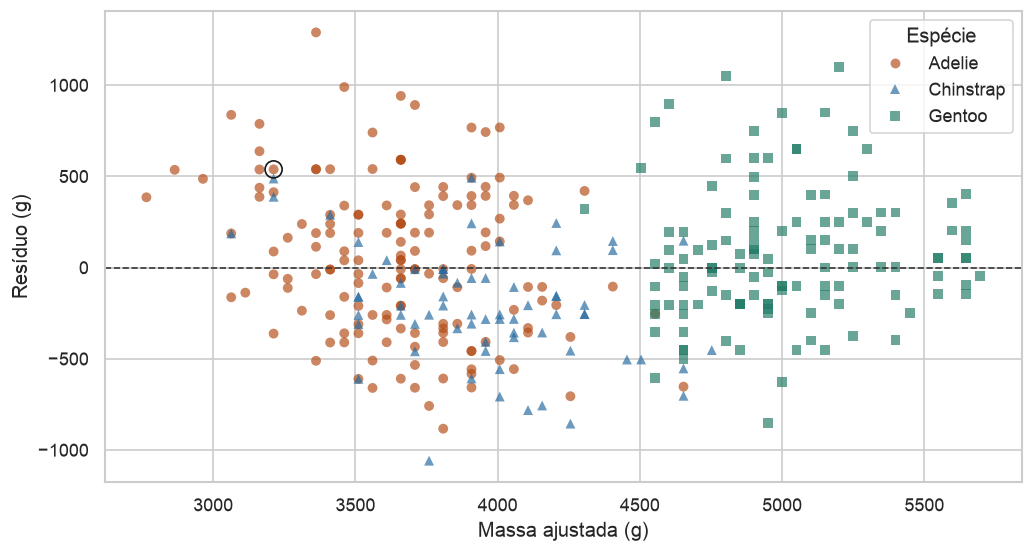

In [22]:
# Desenha os resíduos do modelo simples em relação à massa ajustada.
diag = dados.assign(MASSA_AJUSTADA=ajuste.fittedvalues, RESIDUO=ajuste.resid)
figura, ax = plt.subplots(figsize=(8.5, 4.5), layout="constrained")
dispersao_por_especie(diag, "MASSA_AJUSTADA", "RESIDUO", "Massa ajustada (g)", "Resíduo (g)", ax)
ax.axhline(0, color="#373737", linestyle="--", linewidth=1)
aj_p = b0 + b1 * x_p
ax.scatter(aj_p, y_p - aj_p, facecolor="none", edgecolor="#171717", s=105, zorder=5)
plt.show()

**Figura 10 — Resíduos versus valores ajustados.** O círculo identifica a observação de 181 mm. As cores e os marcadores identificam as espécies. Dados de Horst, Hill e Gorman (2022).

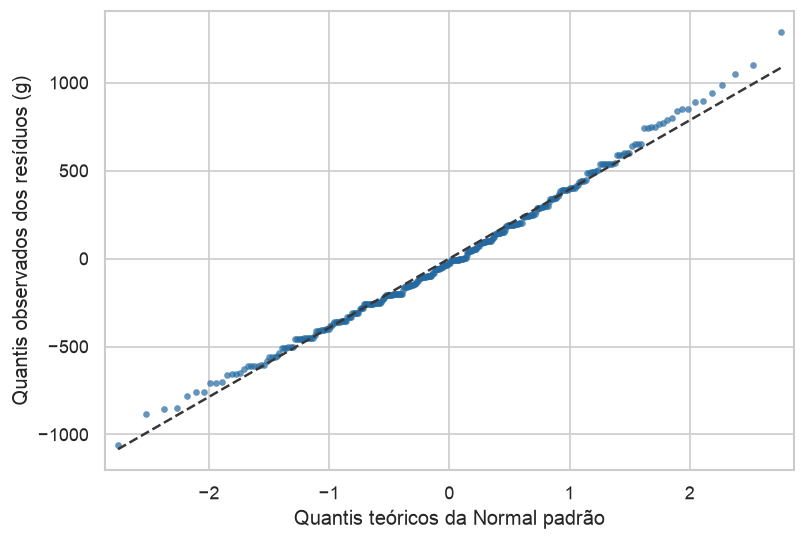

In [23]:
# Compara os quantis observados dos resíduos com os da Normal padrão.
figura, ax = plt.subplots(figsize=(6.6, 4.4), layout="constrained")
qqplot(ajuste.resid.to_numpy(), line="s", ax=ax, markerfacecolor="#2469A0",
       markeredgecolor="none", markersize=4, alpha=0.70)
ax.lines[-1].set_color("#373737")
ax.lines[-1].set_linestyle("--")
ax.set(xlabel="Quantis teóricos da Normal padrão", ylabel="Quantis observados dos resíduos (g)")
plt.show()

**Figura 11 — Gráfico Q–Q Normal dos resíduos.** A reta de referência leva em conta a média e o desvio-padrão dos resíduos. Os eixos exibem quantis teóricos e observados. Dados de Horst, Hill e Gorman (2022).

**Parecer.** O pinguim destacado tem cerca de 3.212 g de massa ajustada e +538 g de resíduo. No gráfico de resíduos, Chinstrap aparece com maior frequência abaixo de zero, e a faixa central de massas ajustadas concentra vários resíduos negativos. A dispersão permanece ampla, sem um funil bem definido. A presença de grupos com posições distintas recomenda cautela ao resumir todas as espécies com a mesma reta.

No Q–Q, os pontos se alinham melhor na região central e há desvios nas caudas, mais visíveis na cauda superior. Isso indica uma aproximação visual à Normal no centro, com diferenças nos extremos. A compatibilidade aproximada no Q–Q é uma avaliação marginal dos resíduos observados.

Os identificadores não se repetem no arquivo analisado. A coleta por ilha e ano admite agrupamentos, por exemplo se pinguins do mesmo local e período compartilharem condições que afetam a massa. Para avaliar essa possibilidade, é preciso considerar o desenho da coleta. A inferência clássica sobre a inclinação deve ser interpretada à luz desses limites e dos padrões por espécie. A próxima aula examina o que muda ao incluir a espécie no modelo.

## 10. Estudo, exercícios e referências

### 10.1. Materiais didáticos

1. **Associação e correlação.** Barbetta, Reis e Bornia, §§ 11.1–11.2.
2. **Regressão simples, ajuste e inferência.** Barbetta, Reis e Bornia, da introdução da § 11.3 até a § 11.3.3.
3. **Coeficiente de determinação ajustado.** Montgomery e Runger, § 12.2.1, trecho da p. 324 sobre o coeficiente ajustado.
4. **Diagnóstico dos resíduos.** Barbetta, Reis e Bornia, § 11.3.4, e Morettin e Bussab, § 16.5, p. 467–470.

### 10.2. Exercícios indicados

Os exercícios são do capítulo 11 de Barbetta, Reis e Bornia (2010).

1. **Interpretar uma reta.** Exercício 5(a–b), p. 344. Estime um valor e interprete a inclinação nas unidades do problema.
2. **Ajustar e testar.** Exercício 6(a, b, d), p. 344. Calcule os coeficientes e o coeficiente de determinação e teste a hipótese de inclinação zero. No item 6(d), calcule o erro-padrão da inclinação e confira-o na saída do ajuste.
3. **Diagnosticar uma reta.** Exercício 9(a–b), p. 345. Ajuste a reta e avalie sua adequação pelo gráfico de resíduos.

### 10.3. Referências

1. BARBETTA, Pedro Alberto; REIS, Marcelo Menezes; BORNIA, Antonio Cezar. *Estatística para cursos de engenharia e informática*. 3. ed. São Paulo: Atlas, 2010.
2. MORETTIN, Pedro Alberto; BUSSAB, Wilton de Oliveira. *Estatística básica*. 6. ed. São Paulo: Saraiva, 2010.
3. MONTGOMERY, Douglas C.; RUNGER, George C. *Applied Statistics and Probability for Engineers*. 7. ed. Hoboken: Wiley, 2018.
4. HORST, Allison M.; HILL, Alison Presmanes; GORMAN, Kristen B. Palmer Archipelago Penguins Data in the palmerpenguins R Package — An Alternative to Anderson's Irises. *The R Journal*, v. 14, n. 1, 2022. [Artigo](https://journal.r-project.org/articles/RJ-2022-020/).
5. NAVIDI, William. *Statistics for Engineers and Scientists*. 6. ed. Nova York: McGraw Hill, 2024.